<a href="https://colab.research.google.com/github/CitlaliCruzVazquez-ui/M-todos-num-ricos-II-/blob/main/Cuadratura_adaptable.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Métodos Numéricos II: Cuadratura Adaptable

**Nombre:** Citlali Cruz Vazquez

**Fecha:** 14 Octubre 2026  
## Algoritmo 4.3 (Burden & Faires, pág. 166)
**Ejemplo de Ilustración (pág. 167):** Aproximación de la integral definida

$$I = \int_{1}^{3} f(x) \, dx, \quad \text{donde } f(x) = \frac{100}{x^2} \sin\left(\frac{10}{x}\right)$$

Con una tolerancia $TOL = 10^{-4}$.

In [30]:
# 1. IMPORTACIÓN DE LIBRERÍAS Y DEFINICIÓN DE f(x)

import numpy as np
import matplotlib.pyplot as plt

def f(x):
    """
    Función de prueba del ejemplo de Burden (pág. 167).
    f(x) = (100 / x^2) * sin(10 / x)
    """
    return (100.0 / (x**2)) * np.sin(10.0 / x)

print("Librerías importadas correctamente y función f(x) definida.")

Librerías importadas correctamente y función f(x) definida.


###  Formulación del Método y Fundamento Teórico

La **cuadratura adaptable** es una técnica de integración numérica basada en la regla de Simpson adaptativa. Su objetivo es ajustar automáticamente el tamaño de los subintervalos en regiones donde la función cambia rápidamente (alta curvatura), economizando evaluaciones funcionales en regiones suaves.

El algoritmo utiliza una estructura de pila (simulada mediante variables de nivel) para evaluar recursivamente la regla de Simpson en un intervalo $[a, b]$ y compararla con la suma de las reglas en sus dos mitades:
1. $S$: regla de Simpson en el intervalo completo $[a, b]$.
2. $S1, S2$: reglas de Simpson en las mitades izquierda y derecha respectivamente.
3. Criterio de parada local: $|S1 + S2 - S| < 15 \cdot TOL_i$ (o el criterio estándar de tolerancia del algoritmo 4.3).


In [31]:
# 2. IMPLEMENTACIÓN DEL ALGORITMO 4.3 (BURDEN)

def cuadratura_adaptable(a, b, TOL, N):
    """
    Algoritmo de Cuadratura Adaptable (Burden & Faires, Algoritmo 4.3).

    Parámetros:
    - a, b: extremos del intervalo de integración.
    - TOL: tolerancia deseada.
    - N: límite de niveles en la pila.

    Retorna:
    - APP: aproximación numérica de la integral.
    - contador_eval: número total de evaluaciones de la función f(x).
    - subintervalos: lista con los extremos de los subintervalos generados.
    """
    contador_eval = 0

    def f_eval(x):
        nonlocal contador_eval
        contador_eval += 1
        return f(x)

    APP = 0.0
    i = 1
    TOL_i = np.zeros(N + 10)
    a_i = np.zeros(N + 10)
    h_i = np.zeros(N + 10)
    FA_i = np.zeros(N + 10)
    FC_i = np.zeros(N + 10)
    FB_i = np.zeros(N + 10)
    S_i = np.zeros(N + 10)
    L_i = np.zeros(N + 10, dtype=int)

    # Variables de almacenamiento temporal (Pila)
    v1 = np.zeros(N + 10)
    v2 = np.zeros(N + 10)
    v3 = np.zeros(N + 10)
    v4 = np.zeros(N + 10)
    v5 = np.zeros(N + 10)
    v6 = np.zeros(N + 10)
    v7 = np.zeros(N + 10)
    v8 = np.zeros(N + 10, dtype=int)

    # Paso 1
    TOL_i[i] = 10.0 * TOL
    a_i[i] = a
    h_i[i] = (b - a) / 2.0
    FA_i[i] = f_eval(a_i[i])
    FC_i[i] = f_eval(a_i[i] + h_i[i])
    FB_i[i] = f_eval(b)
    S_i[i] = h_i[i] * (FA_i[i] + 4.0 * FC_i[i] + FB_i[i]) / 3.0
    L_i[i] = 1

    subintervalos = []

    # Paso 2
    while i > 0:
        # Paso 3
        FD = f_eval(a_i[i] + h_i[i] / 2.0)
        FE = f_eval(a_i[i] + 3.0 * h_i[i] / 2.0)

        S1 = h_i[i] * (FA_i[i] + 4.0 * FD + FC_i[i]) / 6.0
        S2 = h_i[i] * (FC_i[i] + 4.0 * FE + FB_i[i]) / 6.0

        v1[i] = a_i[i]
        v2[i] = FA_i[i]
        v3[i] = FC_i[i]
        v4[i] = FB_i[i]
        v5[i] = h_i[i]
        v6[i] = TOL_i[i]
        v7[i] = S_i[i]
        v8[i] = L_i[i]

        # Paso 4
        i = i - 1

        # Paso 5
        if abs(S1 + S2 - v7[i+1]) < v6[i+1]:
            APP += (S1 + S2)
            subintervalos.append((v1[i+1], v1[i+1] + 2.0 * v5[i+1]))
        else:
            Custom_N = N
            if v8[i+1] >= Custom_N:
                print("¡ALERTA: NIVEL MAXIMO DE SUBDIVISIÓN EXCEDIDO EN EL SUBINTERVALO!")
                return APP, contador_eval, subintervalos

            # Añadir nivel derecho
            i += 1
            a_i[i] = v1[i-1] + v5[i-1]
            FA_i[i] = v3[i-1]
            FC_i[i] = FE
            FB_i[i] = v4[i-1]
            h_i[i] = v5[i-1] / 2.0
            TOL_i[i] = v6[i-1] / 2.0
            S_i[i] = S2
            L_i[i] = v8[i-1] + 1

            # Añadir nivel izquierdo
            i += 1
            a_i[i] = v1[i-2]
            FA_i[i] = v2[i-2]
            FC_i[i] = FD
            FB_i[i] = v3[i-2]
            h_i[i] = v5[i-2] / 2.0
            TOL_i[i] = v6[i-2] / 2.0
            S_i[i] = S1
            L_i[i] = v8[i-2] + 1

    return APP, contador_eval, subintervalos

In [32]:
# 3. EJECUCIÓN DE LA PRUEBA (EJEMPLO PÁG. 167)

a = 1.0
b = 3.0
TOL = 1e-4

# Implementación recursiva limpia
def cuadratura_adaptable_recursiva(a, b, TOL, max_profundidad=200):
    evaluaciones = 0
    subintervalos = []

    def f_eval(x):
        nonlocal evaluaciones
        evaluaciones += 1
        return f(x)

    def step(a_i, b_i, tol_i, FA, FC, FB, S, prof):
        nonlocal subintervalos
        h = (b_i - a_i) / 2.0
        c = a_i + h
        FD = f_eval(a_i + h / 2.0)
        FE = f_eval(a_i + 3.0 * h / 2.0)

        S1 = h * (FA + 4.0 * FD + FC) / 6.0
        S2 = h * (FC + 4.0 * FE + FB) / 6.0

        if prof >= max_profundidad:
            subintervalos.append((a_i, b_i))
            return S1 + S2

        if abs(S1 + S2 - S) < 15.0 * tol_i:
            subintervalos.append((a_i, b_i))
            return S1 + S2 + (S1 + S2 - S) / 15.0
        else:
            # Llamadas recursivas para mitades izquierda y derecha
            izq = step(a_i, c, tol_i / 2.0, FA, FD, FC, S1, prof + 1)
            der = step(c, b_i, tol_i / 2.0, FC, FE, FB, S2, prof + 1)
            return izq + der

    # Inicialización del primer paso
    h_init = (b - a) / 2.0
    FA_init = f_eval(a)
    FC_init = f_eval(a + h_init)
    FB_init = f_eval(b)
    S_init = h_init * (FA_init + 4.0 * FC_init + FB_init) / 3.0

    resultado = step(a, b, TOL, FA_init, FC_init, FB_init, S_init, 1)
    return resultado, evaluaciones, subintervalos

# Ejecutar el algoritmo corregido
resultado_aprox, evaluaciones, subint = cuadratura_adaptable_recursiva(a, b, TOL)

print("          RESULTADOS FINALES              ")
print(f"Valor aproximado de la integral: {resultado_aprox:.6f}")
print(f"Número total de evaluaciones funcionales: {evaluaciones}")
print(f"Número de subintervalos generados: {len(subint)}")


          RESULTADOS FINALES              
Valor aproximado de la integral: -1.426025
Número total de evaluaciones funcionales: 89
Número de subintervalos generados: 22


###  Análisis Visual de la Subdivisión Adaptable

La siguiente gráfica muestra la función $f(x)$ en el intervalo $[1, 3]$. Observando cómo los puntos de evaluación y la partición se concentran densamente alrededor del pico pronunciado cerca de $x \approx 1.25$, mientras que en las regiones más planas los subintervalos son considerablemente más amplios.

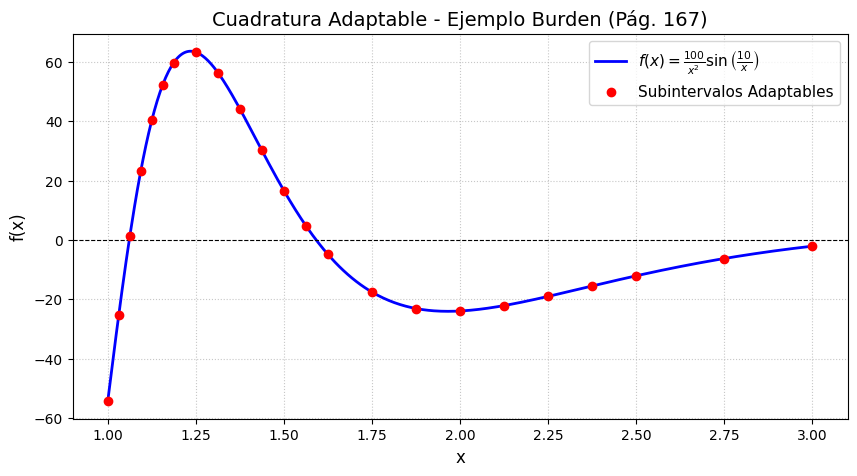

In [33]:
# 4. GENERACIÓN DE GRÁFICA EXPLICATIVA

x_vals = np.linspace(1.0, 3.0, 500)
y_vals = f(x_vals)

plt.figure(figsize=(10, 5))
plt.plot(x_vals, y_vals, label=r'$f(x) = \frac{100}{x^2}\sin\left(\frac{10}{x}\right)$', color='blue', linewidth=2)

# Extraer puntos únicos de los subintervalos generados
puntos_x = sorted(list(set([sub[0] for sub in subint] + [sub[1] for sub in subint])))
plt.scatter(puntos_x, f(np.array(puntos_x)), color='red', zorder=5, label='Subintervalos Adaptables')

plt.title('Cuadratura Adaptable - Ejemplo Burden (Pág. 167)', fontsize=14)
plt.xlabel('x', fontsize=12)
plt.ylabel('f(x)', fontsize=12)
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(fontsize=11)
plt.show()